## 6. Apprentissage d'un RNN sur le corpus de texte Victor HUGO

```
Objectif: Prédire le mot suivant à partir des 3 mots précédents, puis un texte mots après mot. Les exemples d'entraînement et la génération utilisent le même format: une fenétre de 3 mots, complétée par des zéros au début si besoin
```

In [1]:
#importing libraries from libs.py

from libs import *        # np, pd, plt, tf, keras, layers, train_test_split, ...

##### Chargement et nettoyage du corpus

Le fichier brut contient du bruit qui gêne l'apprentissage. Le nettoyage :
- supprime les lignes de métadonnées (`Victor Hugo: ...`, recueil, date, lieu), les titres et les numéros de section (I, II, ...)
- uniformise les apostrophes (`’` → `'`) et retire les guillemets `« »` et tirets `–`
- sépare les élisions (`l'ombre` → `l' ombre`) pour avoir un vocabulaire plus dense
- option `split_verses=True` : découpe les lignes qui contiennent plusieurs vers


In [2]:
import re

COLLECTIONS = [
    "les contemplations", "les feuilles d'automne", "la légende des siècles",
    "odes et ballades", "chansons des rues et des bois", "les rayons et les ombres",
    "l'art d'être grand-père", "les châtiments", "les voix intérieures",
    "l'année terrible", "autrefois", "alentours des chansons", "autour des chansons",
    "la terrasse près enghien",
]
MONTHS = r"janvier|février|mars|avril|mai|juin|juillet|août|septembre|octobre|novembre|décembre"
ELISIONS = r"\b(l|d|j|m|t|s|n|c|qu|jusqu|lorsqu|puisqu|quoiqu)'(?=\w)"


def _norm_title(s):
    return re.sub(r"[\s\.\!\?\,\;\:]+$", "", s.lower().replace("’", "'")).strip()


def _is_meta(line):
    """Short source/date line that follows a 'Victor Hugo:' footer."""
    low = line.lower().replace("’", "'")
    if len(low.split()) > 12:
        return False
    return (any(c in low for c in COLLECTIONS)
            or re.search(r"\b1[5-9]\d\d\b", low) is not None
            or re.search(rf"\b({MONTHS})\b", low) is not None)


def _split_verses(line):
    parts = re.split(r"(?<=[,;:.!?])\s+(?=[A-ZÀ-ÖØ-Þ])", line)
    merged = []
    for p in parts:                       # do not cut after "M." / "Mme." / "St."
        if merged and re.search(r"\b(M|Mme|MM|St|Ste)\.$", merged[-1]):
            merged[-1] += " " + p
        else:
            merged.append(p)
    return merged


def clean_corpus(path, titles_path=None, split_verses=False, split_elisions=True):
    with open(path, encoding="utf-8") as f:
        raw = [l.strip() for l in f if l.strip()]

    titles = set()
    if titles_path:
        with open(titles_path, encoding="utf-8") as f:
            titles = {_norm_title(l) for l in f if l.strip()}

    # 1) supprimer les lignes de métadonnées : "Victor Hugo: ..." + recueil / date / lieu
    kept, i = [], 0
    while i < len(raw):
        line = raw[i]
        if line.startswith("Victor Hugo:"):
            i += 1
            while i < len(raw) and _is_meta(raw[i]):
                i += 1
            continue
        kept.append(line)
        i += 1

    cleaned = []
    for line in kept:
        # 2) supprimer les titres (liste fournie) et les numéros de section (I, II, ...)
        if _norm_title(line) in titles and len(line.split()) <= 10:
            continue
        if re.fullmatch(r"[IVXLC]+\.?", line):
            continue

        # 3) normaliser typographie : apostrophes, guillemets, tirets
        line = line.replace("’", "'").replace("«", " ").replace("»", " ")
        line = line.replace("–", " ").replace("—", " ")
        line = re.sub(r"\s+", " ", line).strip()

        # 4) découper les lignes qui contiennent plusieurs vers
        pieces = _split_verses(line) if split_verses else [line]

        for p in pieces:
            # 5) séparer les élisions : "l'ombre" -> "l' ombre"
            if split_elisions:
                p = re.sub(ELISIONS, r"\1' ", p, flags=re.I)
            # 6) ignorer les lignes trop courtes pour fournir une fenêtre
            if len(re.findall(r"\w+", p)) >= 2:
                cleaned.append(p)
    return cleaned


texts = clean_corpus(
    'victor-hugo-texts.txt',
    titles_path='victor-hugo-titles.txt',   # les titres sont retirés du corpus
    split_verses=False,                      # True : découpe les lignes contenant plusieurs vers
    split_elisions=True                      # "l'ombre" -> "l' ombre"
)

print(f"Nombre de lignes après nettoyage : {len(texts)}")
print(f"Exemple de texte: {texts[0]}")


Nombre de lignes après nettoyage : 1260
Exemple de texte: Mes vers fuiraient, doux et frêles, Vers votre jardin si beau,


In [3]:
vocab = 1000
window_size = 3

tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=vocab)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)

In [4]:
from sklearn.model_selection import train_test_split

# On sépare par LIGNES (et non par fenêtres) : les fenêtres d'une même ligne
# se chevauchent, donc les mélanger entre train et test fausserait l'évaluation.
# Répartition : 80 % train / 10 % validation / 10 % test
seq_train, seq_test = train_test_split(sequences, test_size=0.10, random_state=42)
seq_train, seq_val = train_test_split(seq_train, test_size=1/9, random_state=42)

def make_windows(seqs):
    X, y = [], []
    for seq in seqs:
        for i in range(1, len(seq)):
            X.append(seq[max(0, i - window_size):i])
            y.append(seq[i])
    X = tf.keras.preprocessing.sequence.pad_sequences(
        X, maxlen=window_size, padding="pre"
    )
    return X, np.array(y)

X_train, y_train = make_windows(seq_train)
X_val, y_val = make_windows(seq_val)
X_test, y_test = make_windows(seq_test)

print(f"Train : {X_train.shape}, Validation : {X_val.shape}, Test : {X_test.shape}")


Train : (10121, 3), Validation : (1204, 3), Test : (1340, 3)


In [5]:
embedding_dim = 16

model = keras.Sequential([
    keras.Input(shape=(window_size,)),
    keras.layers.Embedding(input_dim=vocab, output_dim=embedding_dim),
    keras.layers.SimpleRNN(32),
    keras.layers.Dense(vocab, activation="softmax")
])

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 3, 16)          │        16,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1000)           │        33,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,568 (197.53 KB)

 Trainable params: 50,568 (197.53 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop]
)


Epoch 1/100
317/317 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.0317 - loss: 6.0847 - val_accuracy: 0.0282 - val_loss: 5.8600
Epoch 2/100
317/317 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.0373 - loss: 5.7115 - val_accuracy: 0.0341 - val_loss: 5.7907
Epoch 3/100
317/317 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0452 - loss: 5.5826 - val_accuracy: 0.0390 - val_loss: 5.7428
Epoch 4/100
317/317 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.0494 - loss: 5.4762 - val_accuracy: 0.0407 - val_loss: 5.7212
Epoch 5/100
317/317 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0519 - loss: 5.3894 - val_accuracy: 0.0449 - val_loss: 5.7297
Epoch 6/100
317/317 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.0560 - loss: 5.3145 - val_accuracy: 0.0482 - val_loss: 5.7122
Epoch 7/100
317/317 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0650 - loss: 5.2444 - val_accuracy: 0.0540 - val_loss: 5.7191
Epoch 8/100
317/317 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0722 - loss: 5.1746 - val_accu

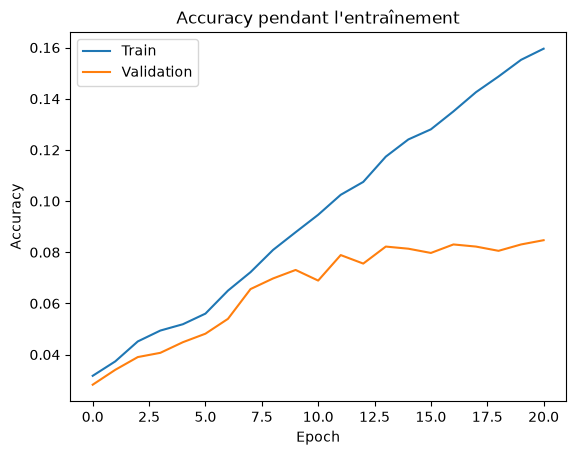

In [7]:
# Analyse de performance du model en graph
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy pendant l'entraînement")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


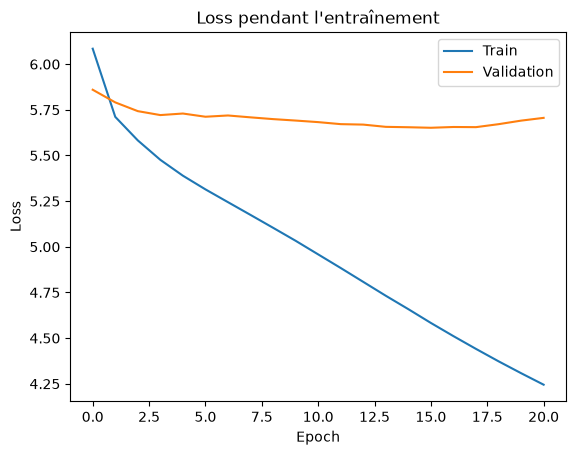

In [8]:
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss pendant l'entraînement")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


##### Évaluation sur le test set (Top-1 / Top-5)

In [9]:
def top_k_scores(X_, y_, k=5):
    probs = model.predict(X_, batch_size=256, verbose=0)
    top1 = np.mean(np.argmax(probs, axis=1) == y_)
    topk_ids = np.argsort(probs, axis=1)[:, -k:]
    topk = np.mean(np.any(topk_ids == y_[:, None], axis=1))
    return top1, topk

for name, (X_, y_) in {"Train": (X_train, y_train),
                       "Validation": (X_val, y_val),
                       "Test": (X_test, y_test)}.items():
    t1, t5 = top_k_scores(X_, y_)
    print(f"{name:<11} Top-1 : {t1:.3f}   Top-5 : {t5:.3f}")

# Référence : toujours prédire le mot le plus fréquent du train
most_common = np.bincount(y_train).argmax()
print(f"\nBaseline (mot le plus fréquent = '{tokenizer.index_word[most_common]}') "
      f"Top-1 sur le test : {np.mean(y_test == most_common):.3f}")


Train       Top-1 : 0.141   Top-5 : 0.326
Validation  Top-1 : 0.080   Top-5 : 0.218
Test        Top-1 : 0.068   Top-5 : 0.196

Baseline (mot le plus fréquent = 'l'') Top-1 sur le test : 0.036


#### Matrix confusion

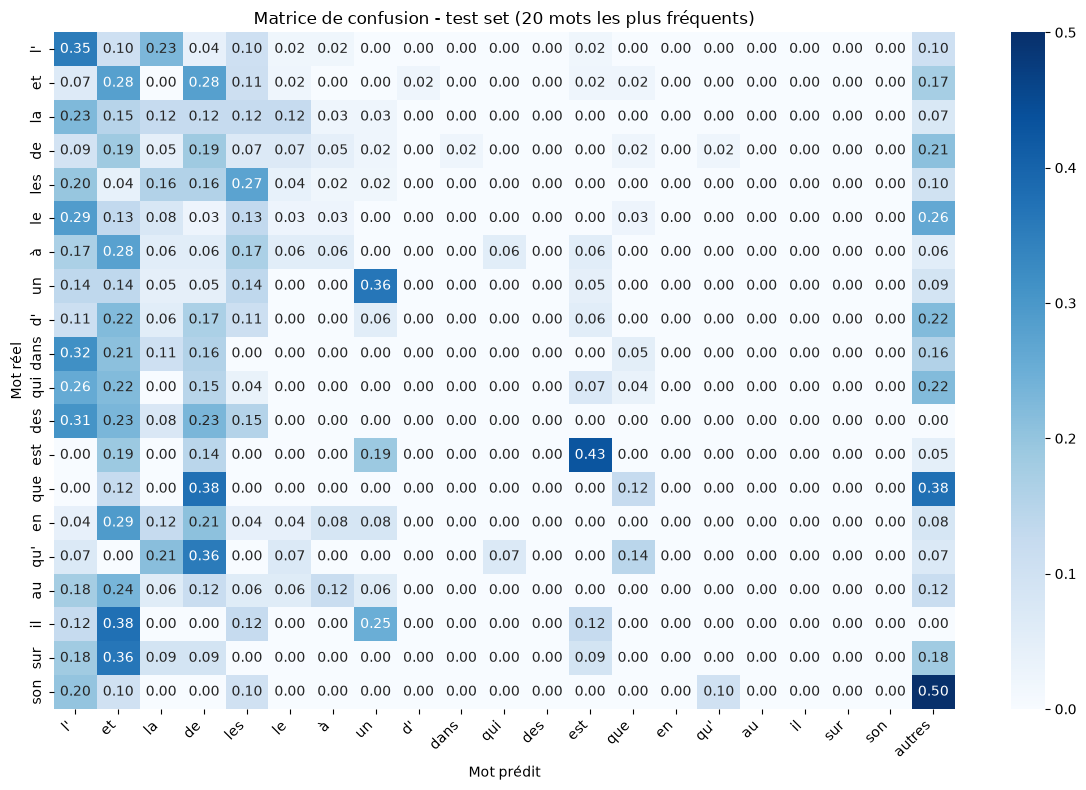

In [10]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Prédictions sur le TEST SET
y_pred = np.argmax(model.predict(X_test, batch_size=256, verbose=0), axis=1)

top_n = 20
freq = np.bincount(y_train, minlength=vocab)          # mots les plus fréquents du train
top_ids = np.argsort(freq)[::-1][:top_n]
labels = [tokenizer.index_word.get(i, str(i)) for i in top_ids]

# on garde les exemples dont le vrai mot est dans le top N ; les autres prédictions deviennent "autres" (-1)
mask = np.isin(y_test, top_ids)
y_true = y_test[mask]
y_hat = np.where(np.isin(y_pred[mask], top_ids), y_pred[mask], -1)

cm = confusion_matrix(y_true, y_hat, labels=list(top_ids) + [-1])[:-1]  # on enlève la ligne vide "autres"
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

plt.figure(figsize=(12, 8))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=labels + ["autres"], yticklabels=labels)
plt.xlabel("Mot prédit")
plt.ylabel("Mot réel")
plt.title(f"Matrice de confusion - test set ({top_n} mots les plus fréquents)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [11]:
errors = pd.Series(list(zip(
    [tokenizer.index_word.get(i) for i in y_test[y_test != y_pred]],
    [tokenizer.index_word.get(i) for i in y_pred[y_test != y_pred]]
))).value_counts().head(10)
print(errors)


(et, de)     13
(le, l')     11
(l', la)     11
(les, l')    10
(la, l')      9
(les, la)     8
(de, et)      8
(les, de)     8
(en, et)      7
(qui, l')     7
Name: count, dtype: int64


In [12]:
from sklearn.metrics import classification_report

top_n = 100
freq = np.bincount(y_train, minlength=vocab)
top_ids = np.argsort(freq)[::-1][:top_n]          # 100 mots les plus fréquents du train
names = [tokenizer.index_word.get(i, str(i)) for i in top_ids]

print(classification_report(
    y_test, y_pred,
    labels=top_ids,
    target_names=names,
    zero_division=0
))


              precision    recall  f1-score   support

          l'       0.09      0.35      0.14        48
          et       0.05      0.28      0.09        46
          la       0.05      0.12      0.07        40
          de       0.05      0.19      0.08        43
         les       0.14      0.27      0.19        51
          le       0.04      0.03      0.03        38
           à       0.03      0.06      0.04        18
          un       0.17      0.36      0.23        22
          d'       0.00      0.00      0.00        18
        dans       0.00      0.00      0.00        19
         qui       0.00      0.00      0.00        27
         des       0.00      0.00      0.00        13
         est       0.38      0.43      0.40        21
         que       0.04      0.12      0.06         8
          en       0.00      0.00      0.00        24
         qu'       0.00      0.00      0.00        14
          au       0.00      0.00      0.00        17
          il       0.00    

In [13]:
def generate_text(start_text, num_words=50, temperature=0.80):
    text = start_text
    for _ in range(num_words):
        #même format qu'à l'entrainement: les 3 derniers mots seulement
        tokens = tokenizer.texts_to_sequences([text])[0][-window_size:]
        tokens = pad_sequences([tokens], maxlen=window_size, padding='pre')
        #probablities du mot suivant
        probs = model.predict(tokens, verbose=0)[0]
        #Tirage pondéré(temperature <1 : plus sûr, >1 : plus varié)
        probs = np.exp(np.log(probs + 1e-9) /temperature)
        probs /= probs.sum()
        index = np.random.choice(len(probs), p=probs)
        
        word = tokenizer.index_word.get(index)
        
        if word is not None:
            text += ' ' +word
            
    return text 

In [14]:
pad_sequences = tf.keras.preprocessing.sequence.pad_sequences
random_text = generate_text("Ce siècle avait deux ans", num_words=50)
print(random_text)

Ce siècle avait deux ans l' envie qui le et la vient sont emportant les grand à l' eaux des compte un jours on perles est le fuit et les cieux de tout là ô humain les morts couchés sous la fièvre dans le nu et l' et le front du enfant et mes toujours
